Universidad Torcuato Di Tella

*Licenciatura en Tecnología Digital*

**Métodos Computacionales — Reconstrucción y regularización en imágenes tomográficas**
# **Trabajo Práctico — Ejercicio N°4**
### ¿Es posible reconstruir la imagen de manera única?

Continuaremos trabajando con la matriz $X_{fantoma}$ y el vector $x_{fantoma}$ del Ejercicio 1, junto con la
función `matriz_proyeccion` implementada anteriormente. El objetivo es investigar si las mediciones
$b = Ax$ contienen información suficiente para recuperar una imagen de $8\times8$ de manera única. Para
ello, analizaremos el rango y el espacio nulo de distintas matrices de proyección.

a) Considerar una matriz de proyección $A \in \mathbb{R}^{m \times 64}$. Utilizando el teorema de rango y nulidad,
determinar qué condición debe cumplir $rango(A)$ para que la imagen pueda reconstruirse de manera única. Explicar qué ocurre si existe un vector no nulo $v$ tal que $Av = 0$ y relacionar $rango(A)$ con $dim(Nul(A))$.

Sea $x_{fantoma}$ la imagen a reconstruir aplanada. Reconstruir la imagen de manera única y unívoca es equivalente a garantizar que el sistema $Ax_{fantoma} = b$ es consistente determinado, es decir, que posee solución única $\forall \ b \in \mathbb{R}^m$. Además, por teorema de la matriz invertible, esto es equivalente a pedir que $A$ sea invertible. Para que esto ocurra, $m$ debe ser igual a $64$ para garantizar que $A$ sea cuadrada, requisito indispensable para asegurar la invertibilidad.

A su vez, por el mismo teorema, esto necesariamente implica que $rango(A) = n = 64$, y por el teorema de rango y nulidad, también implica que $dim(Nul(A)) = 0$. Esta condición se rompe si existe un $v \ne 0$ tal que $Av=0$, en cuyo caso la imagen no se puede reconstruir de manera única.

b) Construir las matrices $A_2$, $A_4$ y $A_7$ utilizando $D_2 = \{(1,0),(0,1)\}$,  $D_4 = D_2 \cup \{(1,1),(1,−1)\}$
y  $D_7 = D_4 \cup \{(2,1),(1,2),(3,1)\}$. Para cada matriz, informar sus dimensiones, su rango, la dimensión de su espacio nulo y si permite determinar una imagen de manera única. Comparar la cantidad de filas con el rango e identificar la presencia de mediciones redundantes.

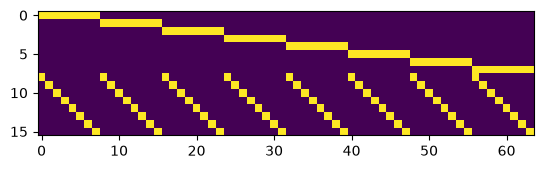

[0.  1.7 3.3 2.3 2.  2.4 1.4 0.  0.  1.7 3.3 2.3 2.  2.4 1.4 0. ]
[0.  1.7 3.3 2.3 2.  2.4 1.4 0. ] [0.  1.7 3.3 2.3 2.  2.4 1.4 0. ]


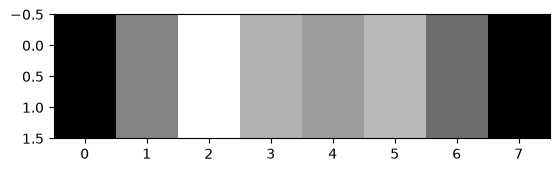

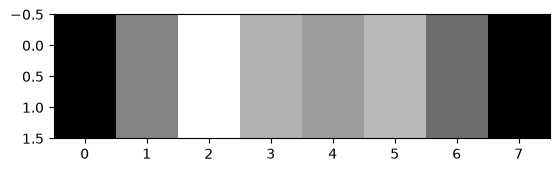

In [1]:
%run ejercicio_3.ipynb

In [10]:
import numpy as np

n = 8

D2 = [(1,0),(0,1)]
D4 = [(1,0),(0,1),(1,1),(1,-1)]
D7 = [(1,0),(0,1),(1,1),(1,-1),(2,1),(1,2),(3,1)]

A2 = matriz_proyeccion(n, D2)[0]
A4 = matriz_proyeccion(n, D4)[0]
A7 = matriz_proyeccion(n, D7)[0]

print("Dimensiones de A2: ", np.shape(A2))
print("Dimensiones de A4: ", np.shape(A4))
print("Dimensiones de A7: ", np.shape(A7), "\n")

print("Rango de A2: ", np.linalg.matrix_rank(A2))
print("Rango de A4: ", np.linalg.matrix_rank(A4))
print("Rango de A7: ", np.linalg.matrix_rank(A7), "\n")

print("dim(Nul A2): ", 64 - np.linalg.matrix_rank(A2))
print("dim(Nul A4): ", 64 - np.linalg.matrix_rank(A4))
print("dim(Nul A7): ", 64 - np.linalg.matrix_rank(A7), "\n")

Dimensiones de A2:  (16, 64)
Dimensiones de A4:  (46, 64)
Dimensiones de A7:  (119, 64) 

Rango de A2:  15
Rango de A4:  39
Rango de A7:  64 

dim(Nul A2):  49
dim(Nul A4):  25
dim(Nul A7):  0 



Dado que, por el momento, ninguna de las matrices obtenidas es cuadrada, no se puede reconstruir la imagen de manera única. Sin embargo, en el caso de $A_7$, se puede observar que $rango(A_7)=64$ y $dim(Nul\ A_7)=0$. Esto implica que contamos con mediciones (filas) redundantes, visto que hay más filas que columnas. Ello no quita que se pueda realizar un análisis de dependencia entre filas para prescindir de aquellas que no aportan información nueva. De esta manera, se puede llegar a una $A_7'$ cuadrada tal que se respete la condición de reconstrucción única.